# LUMA - Lokalny Urok Mistrzostwa Artystycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonosość. 

## Import bibliotek

In [88]:
import numpy as np
import pandas as pd
from itertools import chain
import matplotlib.pyplot as plt

## Wygenerowanie syntetycznych danych

### Ustawienie ziarna RNG

In [2]:
RNG_SEED = 20261020
rng = np.random.default_rng(RNG_SEED)
print("Ustawiono ziarno RNG: ", RNG_SEED)

Ustawiono ziarno RNG:  20261020


 ### Zdefiniowanie "stałych"

In [3]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

### Przygotowanie bazowych danych syntetycznych

"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [4]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], # średni popyt lokalny (szt./tydz.)
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # średni popyt turystyczny (szt./tydz.)
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135], # średnia cena jednostkowa (PLN/szt.)
})

Wyliczony "typowy" przychód tygodniowy: (lokalni + turyśc) * cena

In [5]:
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

In [6]:
display(catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


## Przygotowanie funkcji pomocniczych do generowania danych tygodniowych

Generowanie popytu lokalnego  i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)

In [7]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur 
    
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    
    return df[["category", "demand_loc", "demand_tur"]]

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [8]:
def count_revenue(catalog, demand_df):
    
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]

Generowanie danych tygodniowych

In [9]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych

In [10]:
t1 = generate_weekly_data(catalog, rng)
t1.merge(catalog[['category', 'price_pln_base']], on='category', how='left')
print('Tydzień 1 - przychody per kategoria (PLN)')
display(t1)
print('Łączny przychód w tygodniu 1 (PLN): ', t1['revenue_pln'].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln
0,Ceramika,688,392,1080
1,Tekstylia,21240,3360,24600
2,Biżuteria,13350,11700,25050
3,Rękodzieło,22540,6440,28980
4,Przetwory,7720,3680,11400
5,Dekoracje,4900,1120,6020
6,Stolarka,19000,14250,33250
7,Masarstwo,18275,8815,27090
8,Alkohole,18630,10260,28890


Łączny przychód w tygodniu 1 (PLN):  186360


## Analiza i wizualizacja danych - 1 seria danych

<Axes: >

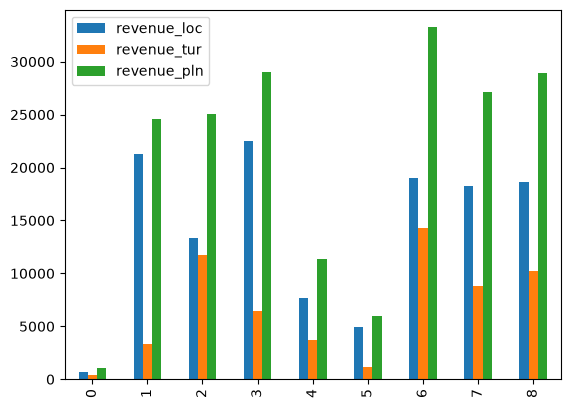

In [11]:
t1.plot.bar()

<Axes: >

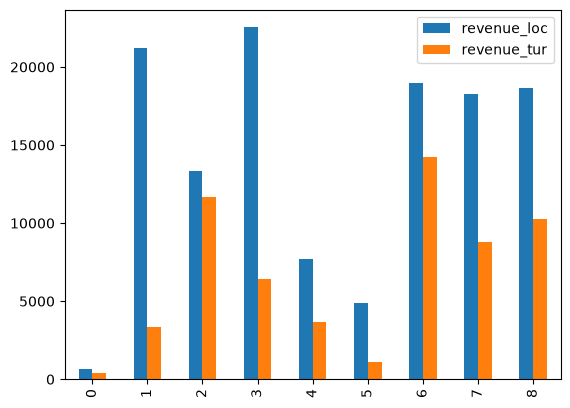

In [12]:
t1[['revenue_loc', 'revenue_tur']].plot.bar()

<Axes: >

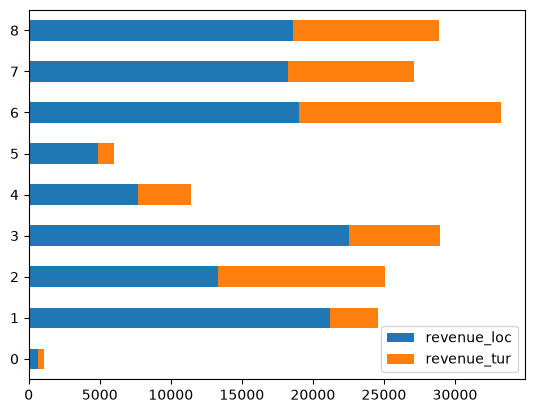

In [13]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

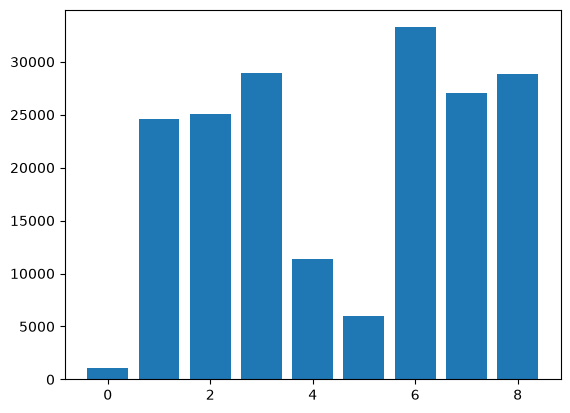

In [14]:
heights = t1['revenue_pln']
plt.bar(range(len(heights)), heights)

Jawne tworzenie i wyświetlanie wykresu

In [15]:
heights = t1['revenue_pln']
categories = t1['category']

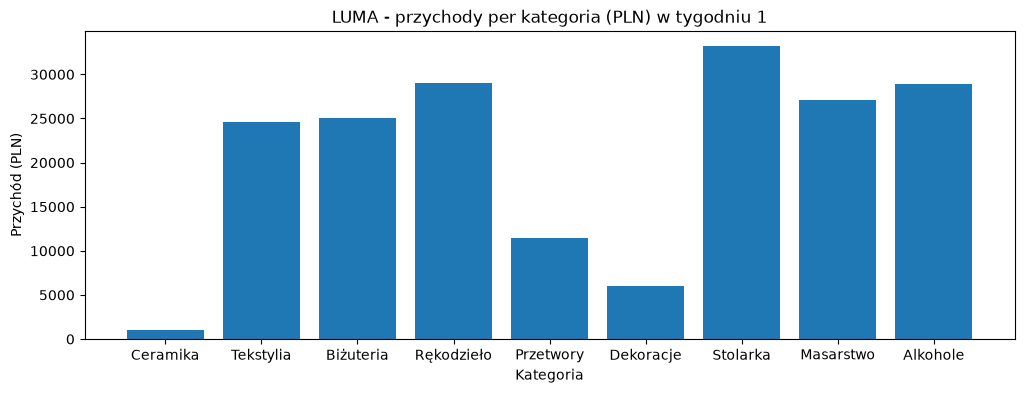

In [16]:
plt.figure(figsize=(12, 4))
plt.bar(categories, heights)
plt.title('LUMA - przychody per kategoria (PLN) w tygodniu 1')
plt.xlabel('Kategoria')
plt.ylabel('Przychód (PLN)')
plt.show()

Etykiety wartości i formatowanie liczb

In [17]:
def format_pln(x: float) -> str:
    return f'{int(round(x)):,} zł'.replace(',', '\u202f')

In [18]:
print(format_pln(123456.789))

123 457 zł


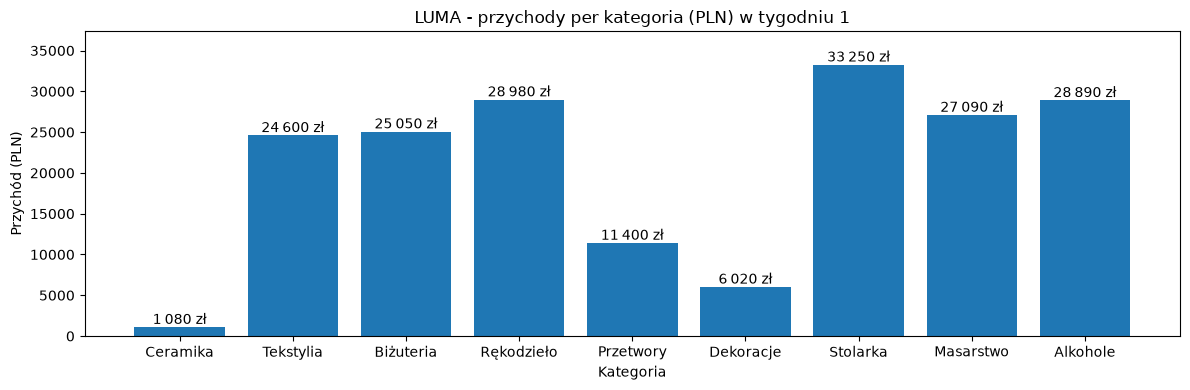

In [19]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
ymin, ymax = plt.ylim() # pobranie wartości min i max dla y
pad = (ymax - ymin) * 0.07
plt.ylim(ymin, ymax + pad) # ustawienie nowej wartości y max
for bar in bars:
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_height()
    plt.text(x, y, format_pln(y), ha='center', va='bottom')
plt.title('LUMA - przychody per kategoria (PLN) w tygodniu 1')
plt.xlabel('Kategoria')
plt.ylabel('Przychód (PLN)')
plt.tight_layout()
plt.show()

In [20]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim() # pobranie wartości min i max dla y
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax + pad) # ustawienie nowej wartości y max

In [21]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha='center', va='bottom')

formatowanie etykiet podziałki osi

In [22]:
def format_tys(x: float, decimals: int = 0) -> str:
    v = x / 1000.0
    if decimals == 0:
        s = f'{int(round(v)):,}'.replace(',', "\u202f")
    else:
        s = f'{v:.{decimals}f}'.replace(',', "\u202f").replace('.', '.')
    return s + ' tys.'

In [23]:
def format_mil(x: float, decimals: int = 0) -> str:
    v = x / 1000000.0
    if decimals == 0:
        s = f'{int(round(v)):,}'.replace(',', "\u202f")
    else:
        s = f'{v:.{decimals}f}'.replace(',', "\u202f").replace('.', '.')
    return s + ' mil.'

In [24]:
print(format_tys(1234567890.456))
print(format_mil(1234567890.456))

1 234 568 tys.
1 235 mil.


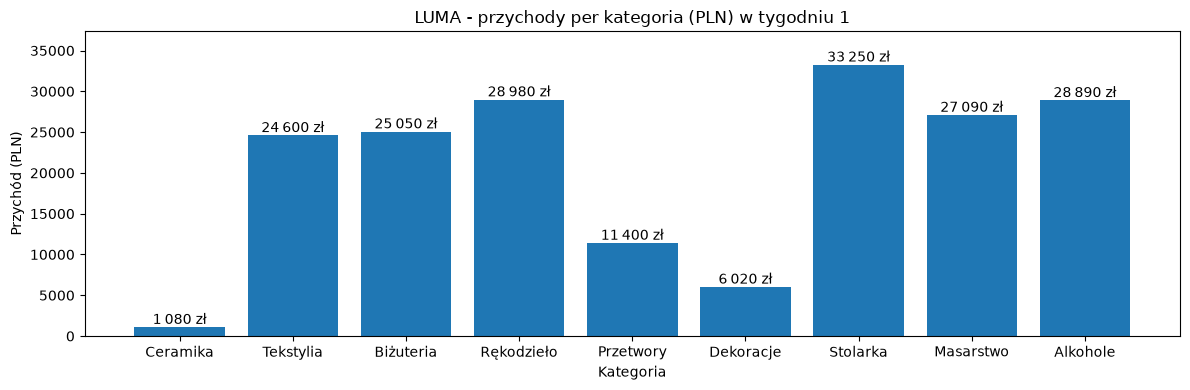

In [25]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
plt.ylim(ymin, ymax + pad) # ustawienie nowej wartości y max
label_bars_pln(bars)
plt.title('LUMA - przychody per kategoria (PLN) w tygodniu 1')
plt.xlabel('Kategoria')
plt.ylabel('Przychód (PLN)')
plt.tight_layout()
plt.show()

In [26]:
def format_ytics_tys():
    ypos, ylab_old = plt.yticks()
    ylab_new = [format_tys(y) for y in ypos]
    plt.yticks(ypos, ylab_new)

Sortowanie kategorii dla łatwiejszego porównania

In [27]:
t1_sorted = t1.sort_values('revenue_pln', ascending=False).reset_index()
categories = t1_sorted['category']
heights = t1_sorted['revenue_pln']

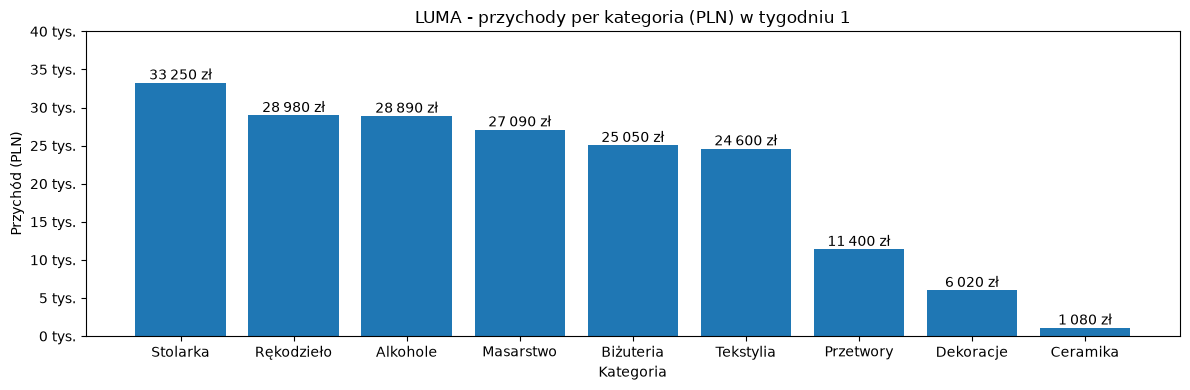

In [28]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.title('LUMA - przychody per kategoria (PLN) w tygodniu 1')
plt.xlabel('Kategoria')
plt.ylabel('Przychód (PLN)')
plt.tight_layout()
plt.show()

Siatka w tle wykresu

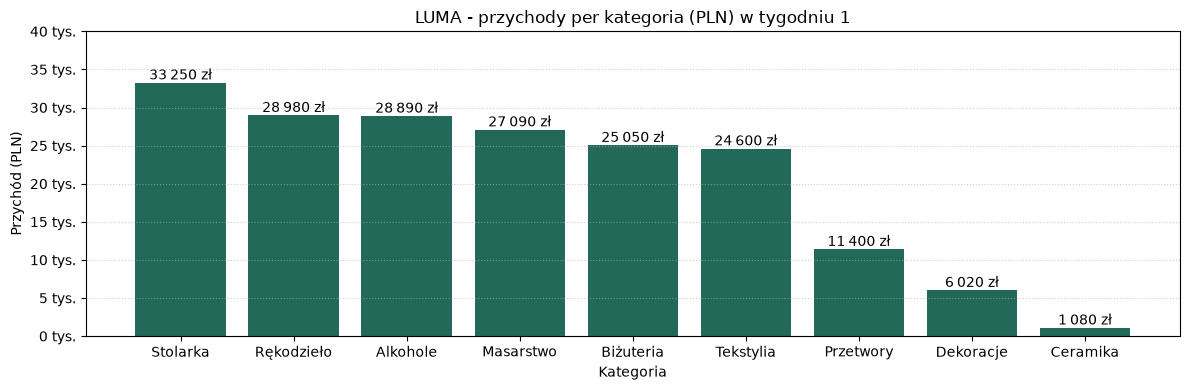

In [29]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights, color='#236959')
pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.title('LUMA - przychody per kategoria (PLN) w tygodniu 1')
plt.xlabel('Kategoria')
plt.ylabel('Przychód (PLN)')
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - 2 serie danych

### Wygenerowanie danych tygodniowych dla 2 tygodnia

Mini-festiwal przyciąga klientów: lokalni +13%, turyści +20%

In [76]:
boost_loc= 0.13
boost_tur = 0.20

t2 = generate_weekly_data(catalog, rng, boost_loc=boost_loc, boost_tur=boost_tur)
t2.merge(catalog[['category', 'price_pln_base']], on='category', how='left')
print('Tydzień 2 - przychody per kategoria (PLN)')
display(t2)
print('Łączny przychód w tygodniu 1: ', format_pln(t1['revenue_pln'].sum()))
print('Łączny przychód w tygodniu 2: ', format_pln(t2['revenue_pln'].sum()))

Tydzień 2 - przychody per kategoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln
0,Ceramika,1048,640,1688
1,Tekstylia,23760,5160,28920
2,Biżuteria,24000,15450,39450
3,Rękodzieło,19090,8740,27830
4,Przetwory,6480,2640,9120
5,Dekoracje,5845,1470,7315
6,Stolarka,23500,16250,39750
7,Masarstwo,21500,10105,31605
8,Alkohole,14040,13500,27540


Łączny przychód w tygodniu 1:  186 360 zł
Łączny przychód w tygodniu 2:  213 218 zł


Przygotowanie danych do wykresu

In [86]:
categories = t1_sorted['category']
t1_revenue_total = t1_sorted['revenue_pln']
t2_revenue_total = t2.set_index('category').loc[categories]['revenue_pln']
x_locs = np.arange(len(categories))
bar_width = 0.4
bar_half = bar_width / 2

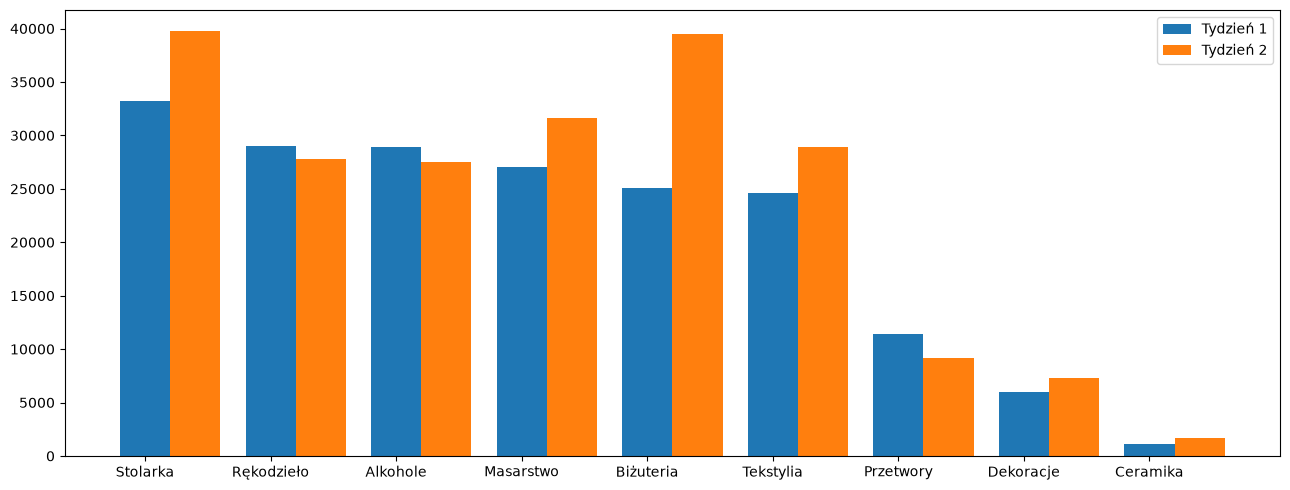

In [87]:
plt.figure(figsize=(13,5))
plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width,
        label="Tydzień 1", tick_label=categories)
plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width,
        label="Tydzień 2")
plt.legend()
plt.tight_layout()
plt.show()

Łączne operowanie na seriach

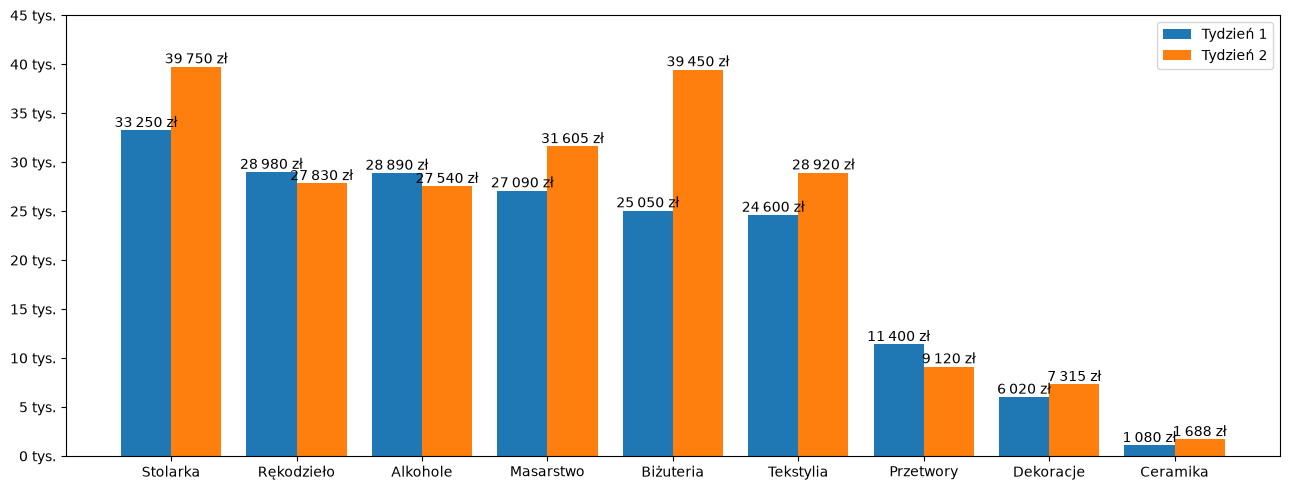

In [89]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width,label="Tydzień 1")
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width,label="Tydzień 2")
plt.xticks(x_locs, categories)
pad_axis()
label_bars_pln(chain(bars_1, bars_2))
format_ytics_tys()
plt.legend()
plt.tight_layout()
plt.show()

In [91]:
def format_sep(x: float) -> str:
    return f'{int(round(x)):,} zł'.replace(',', '\u202f')

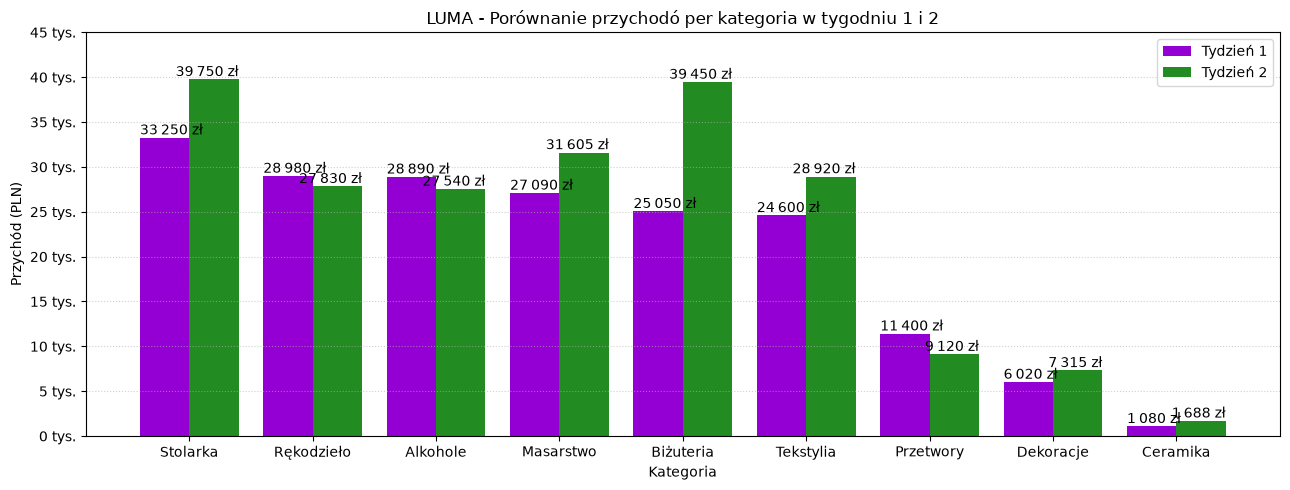

In [ ]:
plt.figure(figsize=(13,5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width,label="Tydzień 1", color='darkviolet')
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width,label="Tydzień 2", color='forestgreen')
plt.xticks(x_locs, categories)
pad_axis()

for b in bars_1:
    x, y = b.get_x(), b.get_height()
    plt.text(x,y, format_sep(y), ha='left', va='bottom')

for b in bars_2:
    x, y = b.get_x() + b.get_width(), b.get_height()
    plt.text(x,y, format_sep(y), ha='right', va='bottom')

format_ytics_tys()

plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.title('LUMA - Porównanie przychodó per kategoria w tygodniu 1 i 2')
plt.xlabel('Kategoria')
plt.ylabel('Przychód (PLN)')

plt.legend()
plt.back
plt.tight_layout()
plt.show()